# Analyzing OpenSLR Hinglish Data

The downloaded dataset has both the train and test splits.

It has the following:
1. Audio file: .wav file for the whole tutorial
2. Transcripts broken in parts

The transcripts have:
| Component | Format | Purpose |
|-----------|--------|---------|
| segments | `<utterance_id> <recording_id> <start> <end>` | start & end time (sec) of every utterance in a recording |
| spk2utt | `<speaker_id> <utterance_id> <utterance_id> ...` | The same data as utt2spk, grouped by speaker |
| spkr_list | `<speaker_id>` | List of speaker IDs |
| text | `<utterance_id> <transcript>` | The transcript of each utterance |
| utt2spk | `<utterance_id> <speaker_id>` | The speaker ID of each utterance |
| wav.scp | `<recording_id> <path to .wav>` | Connects each recording ID to its audio file |

### How the files connect
1. Take an utterance ID from text. This gives you the transcript.
2. Find the same utterance ID in segments. This gives you the recording ID, start time, and end time.
3. Find the recording ID in wav.scp. This gives you the .wav file.
4. Cut the audio from the start time to the end time. This is the clip for that transcript.

## Imports and Path

In [1]:
import wave
from pathlib import Path

import pandas as pd

SPLIT = "train"
PROJECT_ROOT = Path.cwd().parents[1]  # notebooks/analysis -> project root
SPLIT_DIR = PROJECT_ROOT / "data" / "raw" / "hinglish_openslr_raw" / SPLIT
TRANSCRIPTS_DIR = SPLIT_DIR / "transcripts"
OUT_DIR = PROJECT_ROOT / "data" / "interim"
OUT_DIR.mkdir(parents=True, exist_ok=True)

print(SPLIT_DIR, SPLIT_DIR.exists())

/Users/navyajain/Downloads/projects/hinglish-asr/notebooks/data/raw/hinglish_openslr_raw/train False


In [29]:
pd.set_option("display.max_rows", 200)

## Reading the files

In [ ]:
# Path fix: this notebook lives in notebooks/analysis/, so the project root is two levels up
PROJECT_ROOT = Path.cwd().parents[1]
SPLIT_DIR = PROJECT_ROOT / "data" / "raw" / "hinglish_openslr_raw" / SPLIT
TRANSCRIPTS_DIR = SPLIT_DIR / "transcripts"
OUT_DIR = PROJECT_ROOT / "data" / "interim"
OUT_DIR.mkdir(parents=True, exist_ok=True)
print(SPLIT_DIR, SPLIT_DIR.exists())

# Reload the files with the corrected paths
wav_scp = read_two_columns(TRANSCRIPTS_DIR / "wav.scp", "recording_id", "scp_path")
text = read_two_columns(TRANSCRIPTS_DIR / "text", "utt_id", "text")
utt2spk = read_two_columns(TRANSCRIPTS_DIR / "utt2spk", "utt_id", "speaker_id")

segments = pd.DataFrame(
    [line.split() for line in read_lines(TRANSCRIPTS_DIR / "segments")],
    columns=["utt_id", "recording_id", "start", "end"],
)
segments[["start", "end"]] = segments[["start", "end"]].astype(float)
segments["duration"] = segments["end"] - segments["start"]

print(f"wav.scp:  {len(wav_scp):>7,} lines")
print(f"segments: {len(segments):>7,} lines")
print(f"text:     {len(text):>7,} lines")
print(f"utt2spk:  {len(utt2spk):>7,} lines")
wav_scp.head()

/Users/navyajain/Downloads/projects/hinglish-asr/data/raw/hinglish_openslr_raw/train True
wav.scp:      521 lines
segments:  52,825 lines
text:      52,825 lines
utt2spk:   52,825 lines


,recording_id,scp_path
0,0049FmqkWQMNW6Tc,0049FmqkWQMNW6Tc.wav
1,0RDwoEVIUAhVPibN,0RDwoEVIUAhVPibN.wav
2,0RmUBH81UE6b1jFc,0RmUBH81UE6b1jFc.wav
3,0V7yPA2pAqrJrW7Y,0V7yPA2pAqrJrW7Y.wav
4,0ZCBRzDx7vigtAuy,0ZCBRzDx7vigtAuy.wav


## Connecting

`wav.scp` only gives a file name and not a full path. THe following code does that.

In [6]:
# Find the .wav file for each recording in wav.scp
local_wavs = {p.stem: p for p in SPLIT_DIR.glob("*.wav")}


def resolve_wav(recording_id: str, scp_path: str) -> Path | None:
    p = Path(scp_path.split()[-1])  # last token, in case the line has extra fields
    for candidate in (p, SPLIT_DIR / p, SPLIT_DIR / p.name):
        if candidate.is_file():
            return candidate
    return local_wavs.get(p.stem) or local_wavs.get(recording_id)


wav_scp["wav_path"] = [resolve_wav(r, s) for r, s in zip(wav_scp["recording_id"], wav_scp["scp_path"])]
print(f".wav files in folder: {len(local_wavs):,}")
print(f"Recordings with a .wav file: {wav_scp['wav_path'].notna().sum():,} / {len(wav_scp):,}")

.wav files in folder: 521
Recordings with a .wav file: 521 / 521


## Checking headers

A `.wav` file has two parts:

1. Header: a short block at the start, usually 44 bytes. It describes the audio: sample rate, number of channels, bits per sample, and the size of the audio data.
2. Data: the audio samples, one number after the other. This is almost all of the file.

In [7]:
# Read each .wav header (not the audio) to get its format and length
def wav_info(path: Path | None) -> dict:
    if path is None:
        return {"sample_rate": None, "channels": None, "bit_depth": None, "rec_duration": None, "wav_error": "missing"}
    try:
        with wave.open(str(path), "rb") as w:
            return {
                "sample_rate": w.getframerate(),
                "channels": w.getnchannels(),
                "bit_depth": 8 * w.getsampwidth(),
                "rec_duration": w.getnframes() / w.getframerate(),
                "wav_error": None,
            }
    except Exception as e:  # not PCM WAV, or damaged
        return {"sample_rate": None, "channels": None, "bit_depth": None, "rec_duration": None, "wav_error": str(e)}


recordings = pd.concat([wav_scp, pd.DataFrame([wav_info(p) for p in wav_scp["wav_path"]])], axis=1)
recordings[["sample_rate", "channels", "bit_depth", "wav_error"]].value_counts(dropna=False)

sample_rate  channels  bit_depth  wav_error
16000        1         16         NaN          521
Name: count, dtype: int64

## Checks

In [8]:
seg_ids, text_ids, spk_ids = set(segments["utt_id"]), set(text["utt_id"]), set(utt2spk["utt_id"])
rec_with_wav = set(recordings.loc[recordings["wav_path"].notna(), "recording_id"])
good_format = set(
    recordings.query("sample_rate == 16000 and channels == 1 and bit_depth == 16")["recording_id"]
)
rec_len = recordings.set_index("recording_id")["rec_duration"]
seg_rec_len = segments["recording_id"].map(rec_len)

failures = {
    "duplicate utt_id in segments": segments.loc[segments["utt_id"].duplicated(keep=False), "utt_id"],
    "duplicate utt_id in text": text.loc[text["utt_id"].duplicated(keep=False), "utt_id"],
    "duplicate utt_id in utt2spk": utt2spk.loc[utt2spk["utt_id"].duplicated(keep=False), "utt_id"],
    "duplicate recording_id in wav.scp": wav_scp.loc[wav_scp["recording_id"].duplicated(keep=False), "recording_id"],
    "in segments, not in text": pd.Series(sorted(seg_ids - text_ids)),
    "in text, not in segments": pd.Series(sorted(text_ids - seg_ids)),
    "in segments, not in utt2spk": pd.Series(sorted(seg_ids - spk_ids)),
    "in utt2spk, not in segments": pd.Series(sorted(spk_ids - seg_ids)),
    "segment recording has no .wav file": segments.loc[~segments["recording_id"].isin(rec_with_wav), "utt_id"],
    ".wav not 16 kHz mono 16-bit": recordings.loc[
        recordings["wav_path"].notna() & ~recordings["recording_id"].isin(good_format), "recording_id"
    ],
    "start >= end": segments.loc[segments["start"] >= segments["end"], "utt_id"],
    "segment ends after recording (> 0.01 s)": segments.loc[segments["end"] > seg_rec_len + 0.01, "utt_id"],
    "empty transcript": text.loc[text["text"].str.strip() == "", "utt_id"],
}

summary = pd.DataFrame(
    {"failures": {k: len(v) for k, v in failures.items()},
     "examples": {k: list(v.head(5)) for k, v in failures.items()}}
)
summary

,failures,examples
duplicate utt_id in segments,0,[]
duplicate utt_id in text,0,[]
duplicate utt_id in utt2spk,0,[]
duplicate recording_id in wav.scp,0,[]
"in segments, not in text",0,[]
"in text, not in segments",0,[]
"in segments, not in utt2spk",0,[]
"in utt2spk, not in segments",0,[]
segment recording has no .wav file,0,[]
.wav not 16 kHz mono 16-bit,0,[]


## Joining in 1 Table

In [9]:
utterances = (
    segments
    .merge(text, on="utt_id", how="left")
    .merge(utt2spk, on="utt_id", how="left")
    .merge(recordings[["recording_id", "wav_path", "rec_duration"]], on="recording_id", how="left")
)
utterances["wav_path"] = utterances["wav_path"].map(lambda p: str(p) if isinstance(p, Path) else None)

print(f"Utterances: {len(utterances):,}")
print(f"Recordings: {utterances['recording_id'].nunique():,}")
print(f"Speaker IDs: {utterances['speaker_id'].nunique():,}")
print(f"Total hours: {utterances['duration'].sum() / 3600:.2f}")

out_path = OUT_DIR / f"openslr104_{SPLIT}_utterances.parquet"
utterances.to_parquet(out_path, index=False)
print(f"Saved: {out_path}")
utterances.head()

Utterances: 52,825
Recordings: 521
Speaker IDs: 520
Total hours: 89.55
Saved: /Users/navyajain/Downloads/projects/hinglish-asr/data/interim/openslr104_train_utterances.parquet


,utt_id,recording_id,start,end,duration,text,speaker_id,wav_path,rec_duration
0,100051_GigsEKRBMhvNwolC_0000,GigsEKRBMhvNwolC,0.0,9.0,9.0,दोस्तों bash में nested और multilevel if state...,100051,/Users/navyajain/Downloads/projects/hinglish-a...,697.08
1,100051_GigsEKRBMhvNwolC_0001,GigsEKRBMhvNwolC,9.0,12.0,3.0,इस tutorial में हम निम्न के बारे में सीखेंगे,100051,/Users/navyajain/Downloads/projects/hinglish-a...,697.08
2,100051_GigsEKRBMhvNwolC_0002,GigsEKRBMhvNwolC,12.0,14.0,2.0,nested ifelse और,100051,/Users/navyajain/Downloads/projects/hinglish-a...,697.08
3,100051_GigsEKRBMhvNwolC_0003,GigsEKRBMhvNwolC,14.0,17.0,3.0,multilevel ifelse statement,100051,/Users/navyajain/Downloads/projects/hinglish-a...,697.08
4,100051_GigsEKRBMhvNwolC_0004,GigsEKRBMhvNwolC,17.0,22.0,5.0,हम यह कुछ उदाहरण उपयोग करके करेंगे,100051,/Users/navyajain/Downloads/projects/hinglish-a...,697.08


## Split by recording into train/val

All utterances from one recording must go into the same split. If one tutorial is in both train and validation, the validation WER is too optimistic.

Method:
- Calculate the hours of each recording.
- Shuffle the recordings with a fixed seed.
- Put recordings into validation until it has about 5% of the hours.

In [10]:
import unicodedata
from pathlib import Path

import numpy as np
import pandas as pd

PROJECT_ROOT = Path.cwd().parents[1]
INTERIM_DIR = PROJECT_ROOT / "data" / "interim"

VAL_SHARE = 0.05  # share of hours for validation
SEED = 42         # fixed seed, so the split is the same each time

utts = pd.read_parquet(INTERIM_DIR / "openslr104_train_utterances.parquet")
print(f"{len(utts):,} utterances, {utts['recording_id'].nunique()} recordings")

52,825 utterances, 521 recordings


In [11]:
rec_hours = utts.groupby("recording_id")["duration"].sum().div(3600).rename("hours")
rec_hours.describe()

count    521.000000
mean       0.171888
std        0.056515
min        0.052067
25%        0.136119
50%        0.168350
75%        0.200025
max        0.590019
Name: hours, dtype: float64

- A typical recording is about 10 minutes long (mean = 0.171888 hours or 10.3 mins, median 10.1).
- The shortest is about 3 minutes and the longest is about 35 minutes.
- Total: 521 × 0.1719 ≈ 89.55 hours.

The recordings are similar in length and no single recording is very large. So a 5% validation split will be about 26 recordings and 4.5 hours.

### Select the validation recordings

Shuffle the recordings, then add them to validation until the total reaches 5% of the hours.

In [12]:
rng = np.random.default_rng(SEED)
order = rng.permutation(rec_hours.index.to_numpy())
cum_hours = rec_hours.loc[order].cumsum()
target_hours = VAL_SHARE * rec_hours.sum()

val_recs = set(cum_hours[cum_hours <= target_hours].index)
utts["split"] = np.where(utts["recording_id"].isin(val_recs), "validation", "train")

In [13]:
train_recs = set(utts.loc[utts["split"] == "train", "recording_id"])
assert not (train_recs & val_recs), "A recording is in both splits"

utts.groupby("split").agg(
    utterances=("utt_id", "size"),
    recordings=("recording_id", "nunique"),
    hours=("duration", lambda s: s.sum() / 3600),
)

,utterances,recordings,hours
split,,,
train,50315,496,85.173281
validation,2510,25,4.380317


In [14]:
utts.to_parquet(INTERIM_DIR / "openslr104_train_utterances_split.parquet", index=False)

## Check for leaks into the test set

In [16]:
MIN_WORDS = 3  # short identical phrases (for example, a greeting) are not real leaks

TEST_RAW = PROJECT_ROOT / "data" / "raw" / "hinglish_openslr_test_raw"
TEST_TRANSCRIPTS = next(TEST_RAW.rglob("wav.scp")).parent  # finds the transcripts folder
print(TEST_TRANSCRIPTS)


def read_lines(path: Path) -> list[str]:
    with path.open(encoding="utf-8") as f:
        return [line.rstrip("\n") for line in f if line.strip()]


def read_two_columns(path: Path, id_col: str, value_col: str) -> pd.DataFrame:
    rows = []
    for line in read_lines(path):
        parts = line.split(maxsplit=1)
        rows.append((parts[0], parts[1] if len(parts) > 1 else ""))
    return pd.DataFrame(rows, columns=[id_col, value_col])


def load_kaldi(transcripts_dir: Path) -> pd.DataFrame:
    """One row per utterance: segments + text + speaker ID."""
    seg = pd.DataFrame(
        [line.split() for line in read_lines(transcripts_dir / "segments")],
        columns=["utt_id", "recording_id", "start", "end"],
    )
    seg[["start", "end"]] = seg[["start", "end"]].astype(float)
    seg["duration"] = seg["end"] - seg["start"]
    text = read_two_columns(transcripts_dir / "text", "utt_id", "text")
    utt2spk = read_two_columns(transcripts_dir / "utt2spk", "utt_id", "speaker_id")
    return seg.merge(text, on="utt_id", how="left").merge(utt2spk, on="utt_id", how="left")


train = pd.read_parquet(INTERIM_DIR / "openslr104_train_utterances_split.parquet")
test = load_kaldi(TEST_TRANSCRIPTS)

print(f"Train: {len(train):,} utterances, {train['recording_id'].nunique()} recordings, {train['duration'].sum() / 3600:.2f} h")
print(f"Test:  {len(test):,} utterances, {test['recording_id'].nunique()} recordings, {test['duration'].sum() / 3600:.2f} h")
print(f"Test utterances without text: {test['text'].isna().sum()}, without speaker: {test['speaker_id'].isna().sum()}")

test.to_parquet(INTERIM_DIR / "openslr104_test_utterances.parquet", index=False)

/Users/navyajain/Downloads/projects/hinglish-asr/data/raw/hinglish_openslr_test_raw/test/transcripts
Train: 52,825 utterances, 521 recordings, 89.55 h
Test:  3,136 utterances, 30 recordings, 5.18 h
Test utterances without text: 0, without speaker: 0


### Shared recordings and speakers

In [17]:
shared_recs = set(train["recording_id"]) & set(test["recording_id"])
shared_spks = set(train["speaker_id"]) & set(test["speaker_id"])

print(f"Recordings in both: {len(shared_recs)}")
print(f"Speaker IDs in both: {len(shared_spks)}")

Recordings in both: 0
Speaker IDs in both: 0


### Identical transcripts

This is not the final normalizer. It only makes sure that small differences in spaces do not hide a match.

In [18]:
def light_norm(s: str) -> str:
    return " ".join(unicodedata.normalize("NFC", s).lower().split())


train["text_key"] = train["text"].map(light_norm)
test["text_key"] = test["text"].map(light_norm)
train["n_words"] = train["text_key"].str.split().str.len()

in_test = train["text_key"].isin(set(test["text_key"]))
test_in_train = test["text_key"].isin(set(train["text_key"]))

print(f"Train utterances with a transcript identical to a test transcript: {in_test.sum():,}")
print(f"  of these, with {MIN_WORDS} or more words: {(in_test & (train['n_words'] >= MIN_WORDS)).sum():,}")
print(f"Test utterances with a transcript also in train: {test_in_train.sum():,} ({test_in_train.mean():.1%})")

train.loc[in_test, "text_key"].value_counts().head(20)

Train utterances with a transcript identical to a test transcript: 3,303
  of these, with 3 or more words: 3,244
Test utterances with a transcript also in train: 1,303 (41.5%)


text_key
यह spoken tutorial project को सारांशित करता है                                                        166
अच्छी bandwidth न मिलने पर आप इसे download करके देख सकते हैं                                          110
निम्न link पर उपलब्ध video देखें                                                                      105
spoken tutorial project talktoa teacher project का हिस्सा है                                           97
यह भारत सरकार के एमएचआरडी के आईसीटी के माध्यम से राष्ट्रीय साक्षरता mission द्वारा समर्थित है          91
spoken tutorial project team                                                                           89
online test pass करने वालों को प्रमाणपत्र देते हैं                                                     83
आई आई टी बॉम्बे से मैं श्रुति आर्य आपसे विदा लेती हूँ हमसे जुड़ने के लिए धन्यवाद                       79
इस mission पर अधिक जानकारी निम्न लिंक पर उपलब्ध है                                                     78
यह भारत सरकार के it it आर डी के आई सी

### Remove the leaks from train

Remove from train (and validation):
- all utterances from a recording that is also in test,
- utterances with a transcript identical to a test transcript and with `MIN_WORDS` or more words.

Save the removed utterances with the reason for each.

In [19]:
reason = pd.Series("", index=train.index)
reason.loc[train["recording_id"].isin(shared_recs)] = "recording in test"
reason.loc[in_test & (train["n_words"] >= MIN_WORDS) & (reason == "")] = "transcript identical to test"

removed = train.loc[reason != "", ["utt_id", "recording_id", "split", "text"]].assign(reason=reason[reason != ""])
clean = train.loc[reason == ""].drop(columns=["text_key", "n_words"])

print(removed["reason"].value_counts())
print(f"Removed: {len(removed):,} utterances, {train.loc[reason != '', 'duration'].sum() / 3600:.2f} h")
print(f"Remaining: {len(clean):,} utterances, {clean['duration'].sum() / 3600:.2f} h")

removed.to_csv(INTERIM_DIR / "openslr104_train_removed_leaks.csv", index=False)
clean.to_parquet(INTERIM_DIR / "openslr104_train_utterances_noleak.parquet", index=False)

reason
transcript identical to test    3244
Name: count, dtype: int64
Removed: 3,244 utterances, 4.54 h
Remaining: 49,581 utterances, 85.02 h


## 5. Filter durations

- Remove clips under 0.5 s: they are usually noise or cut-off words.
- Remove clips over 20 s: they use too much GPU memory in training.

count    49581.00
mean         6.17
std          3.50
min          0.50
1%           2.00
5%           2.00
50%          5.00
95%         12.00
99%         19.00
max         57.00
Name: duration, dtype: float64
< 0.5 s:      0 clips, 0.00 h
  < 1 s:      6 clips, 0.00 h
 > 20 s:    339 clips, 2.44 h
 > 30 s:     55 clips, 0.56 h


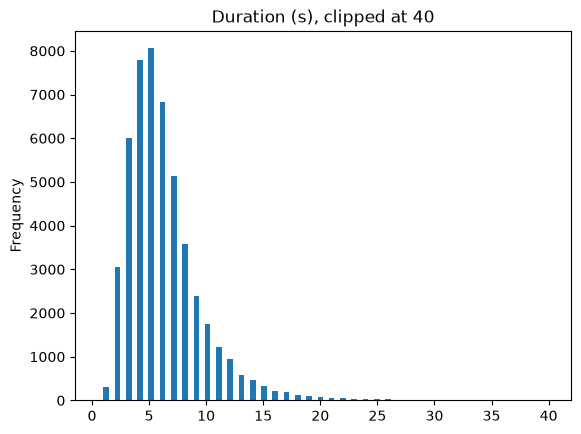

In [20]:
MIN_SEC, MAX_SEC = 0.5, 20.0

utts = pd.read_parquet(INTERIM_DIR / "openslr104_train_utterances_noleak.parquet")
d = utts["duration"]

print(d.describe(percentiles=[0.01, 0.05, 0.5, 0.95, 0.99]).round(2))
for label, mask in {
    "< 0.5 s": d < 0.5, "< 1 s": d < 1, "> 20 s": d > 20, "> 30 s": d > 30,
}.items():
    print(f"{label:>7}: {mask.sum():>6,} clips, {d[mask].sum() / 3600:.2f} h")

d.clip(upper=40).plot.hist(bins=80, title="Duration (s), clipped at 40");

In [21]:
too_short, too_long = d < MIN_SEC, d > MAX_SEC

removed = pd.concat([
    utts.loc[too_short, ["utt_id", "duration", "text"]].assign(reason=f"under {MIN_SEC} s"),
    utts.loc[too_long, ["utt_id", "duration", "text"]].assign(reason=f"over {MAX_SEC} s"),
])
kept = utts.loc[~(too_short | too_long)]

print(removed["reason"].value_counts())
print(f"Kept: {len(kept):,} clips, {kept['duration'].sum() / 3600:.2f} h")

removed.to_csv(INTERIM_DIR / "openslr104_train_removed_duration.csv", index=False)
kept.to_parquet(INTERIM_DIR / "openslr104_train_utterances_filtered.parquet", index=False)

reason
over 20.0 s    339
Name: count, dtype: int64
Kept: 49,242 clips, 82.58 h


## Find English words written in Devanagari

Some English words are written in Latin script and some in Devanagari, for example "file" and "फ़ाइल". The output must use Latin script for all English words.

Method:
- Convert each unique Devanagari word to Latin letters with simple rules.
- Reduce each word to a consonant key (for example, "terminal" → "trmnl"), because vowels are spelled differently in the two scripts.
- Match the keys against the Latin words in the corpus.
- Review the candidates by hand.

Limit: this finds only English words that also occur in Latin script somewhere in the corpus.

In [22]:
import re
from collections import Counter
from difflib import SequenceMatcher

utts = pd.read_parquet(INTERIM_DIR / "openslr104_train_utterances_filtered.parquet")

DEVA = re.compile(r"^[\u0900-\u097F]+$")
LATIN = re.compile(r"^[A-Za-z]+$")

words = Counter(w for t in utts["text"] for w in unicodedata.normalize("NFC", t).split())
deva_counts = {w: c for w, c in words.items() if DEVA.match(w)}
latin_counts = Counter()
for w, c in words.items():
    if LATIN.match(w):
        latin_counts[w.lower()] += c

total = sum(words.values())
print(f"Unique Devanagari words: {len(deva_counts):,} ({sum(deva_counts.values()) / total:.1%} of all words)")
print(f"Unique Latin words:      {len(latin_counts):,} ({sum(latin_counts.values()) / total:.1%} of all words)")

Unique Devanagari words: 8,154 (73.5% of all words)
Unique Latin words:      6,503 (24.1% of all words)


In [23]:
CONS = {"क": "k", "ख": "kh", "ग": "g", "घ": "gh", "ङ": "n", "च": "ch", "छ": "chh", "ज": "j", "झ": "jh", "ञ": "n",
        "ट": "t", "ठ": "th", "ड": "d", "ढ": "dh", "ण": "n", "त": "t", "थ": "th", "द": "d", "ध": "dh", "न": "n",
        "प": "p", "फ": "ph", "ब": "b", "भ": "bh", "म": "m", "य": "y", "र": "r", "ल": "l", "ळ": "l", "व": "v",
        "श": "sh", "ष": "sh", "स": "s", "ह": "h"}
NUKTA_CONS = {"क": "q", "ख": "kh", "ग": "g", "ज": "z", "ड": "r", "ढ": "rh", "फ": "f", "य": "y"}
PRECOMPOSED = {"\u0958": "क\u093c", "\u0959": "ख\u093c", "\u095a": "ग\u093c", "\u095b": "ज\u093c",
               "\u095c": "ड\u093c", "\u095d": "ढ\u093c", "\u095e": "फ\u093c", "\u095f": "य\u093c"}
VOWELS = {"अ": "a", "आ": "aa", "इ": "i", "ई": "ee", "उ": "u", "ऊ": "oo", "ऋ": "ri", "ए": "e", "ऐ": "ai",
          "ओ": "o", "औ": "au", "ऑ": "o", "ऍ": "e"}
MATRAS = {"ा": "aa", "ि": "i", "ी": "ee", "ु": "u", "ू": "oo", "ृ": "ri", "े": "e", "ै": "ai",
          "ो": "o", "ौ": "au", "ॉ": "o", "ॅ": "e"}
VIRAMA, NUKTA = "\u094d", "\u093c"


def romanize(word: str) -> str:
    """Convert a Devanagari word to Latin letters with simple rules."""
    for k, v in PRECOMPOSED.items():
        word = word.replace(k, v)
    out, i, n = [], 0, len(word)
    while i < n:
        ch = word[i]
        if ch in CONS:
            nxt = word[i + 1] if i + 1 < n else ""
            if nxt == NUKTA:
                out.append(NUKTA_CONS.get(ch, CONS[ch]))
                i += 1
                nxt = word[i + 1] if i + 1 < n else ""
            else:
                out.append(CONS[ch])
            if nxt in MATRAS:
                out.append(MATRAS[nxt])
                i += 1
            elif nxt == VIRAMA:
                i += 1
            elif i + 1 < n:
                out.append("a")  # inherent vowel, dropped at the end of a word
        elif ch in VOWELS:
            out.append(VOWELS[ch])
        elif ch in "ंँ":
            nxt = word[i + 1] if i + 1 < n else ""
            out.append("m" if nxt in "पफबभम" else "n")
        elif ch == "ः":
            out.append("h")
        i += 1
    return "".join(out)


def key(s: str, latin: bool = False) -> str:
    """Consonant key: same sounds give the same key in both scripts."""
    s = s.lower()
    if latin:
        s = s.replace("ch", "C")
        s = re.sub(r"c(?=[eiy])", "s", s).replace("c", "k").replace("C", "c")
    for a, b in [("chh", "c"), ("ch", "c"), ("sh", "s"), ("ph", "f"), ("th", "t"), ("dh", "d"), ("kh", "k"),
                 ("gh", "g"), ("bh", "b"), ("jh", "j"), ("ck", "k"), ("q", "k"), ("w", "v"), ("z", "j"), ("x", "ks")]:
        s = s.replace(a, b)
    s = re.sub(r"[aeiouyh]", "", s)
    return re.sub(r"(.)\1+", r"\1", s)


# Quick check
for d, e in [("ट्यूटोरियल", "tutorial"), ("फ़ाइल", "file"), ("कंप्यूटर", "computer"), ("फल", "file")]:
    r = romanize(unicodedata.normalize("NFC", d))
    print(d, r, key(r) == key(e, latin=True), round(SequenceMatcher(None, r, e).ratio(), 2))

ट्यूटोरियल tyootoriyal True 0.74
फ़ाइल faail True 0.67
कंप्यूटर kampyootar True 0.44
फल phal True 0.25


In [42]:
MIN_SIMILARITY = 0.4  # rejects false matches such as फल (fruit) → "file"
CHUNK_SIZE = 200
CHUNK_DIR = INTERIM_DIR / "loanword_candidates"
CHUNK_DIR.mkdir(parents=True, exist_ok=True)

latin_by_key = {}
for w in latin_counts:
    latin_by_key.setdefault(key(w, latin=True), []).append(w)

rows = []
for dw, dc in deva_counts.items():
    r = romanize(dw)
    k = key(r)
    if len(k) < 2 or k not in latin_by_key:
        continue
    best = max(latin_by_key[k], key=lambda e: SequenceMatcher(None, r, e).ratio())
    sim = SequenceMatcher(None, r, best).ratio()
    if sim >= MIN_SIMILARITY:
        rows.append((dw, dc, r, best, latin_counts[best], round(sim, 2)))

cands = pd.DataFrame(rows, columns=["devanagari", "deva_count", "romanized", "english", "latin_count", "similarity"])
cands = cands.sort_values("deva_count", ascending=False).reset_index(drop=True)
cands["accept"] = ""  # 1 = English word, 0 = Hindi word

n_parts = -(-len(cands) // CHUNK_SIZE)  # round up
for i in range(n_parts):
    part = cands.iloc[i * CHUNK_SIZE:(i + 1) * CHUNK_SIZE]
    part.to_csv(CHUNK_DIR / f"loanword_candidates_part{i + 1:02d}.csv", index=False, encoding="utf-8-sig")

print(f"Candidates: {len(cands):,}, covering {cands['deva_count'].sum():,} word occurrences")
print(f"Saved {n_parts} files of up to {CHUNK_SIZE} rows to {CHUNK_DIR}")
cands.head()

Candidates: 3,825, covering 151,467 word occurrences
Saved 20 files of up to 200 rows to /Users/navyajain/Downloads/projects/hinglish-asr/data/interim/loanword_candidates


,devanagari,deva_count,romanized,english,latin_count,similarity,accept
0,पर,13365,par,pair,6,0.86,
1,करें,11265,karem,cream,3,0.60,
2,करने,3667,karane,karen,6,0.73,
3,कर,2866,kar,car,13,0.67,
4,उपयोग,2447,upayog,page,147,0.60,


### Note

This is where I downloaded the loanword candidates and parsed them via Claude chat to get results.

## Combine the loanword annotations

Combine the annotated files, check them against the original candidates, and save the final loanword list.

In [45]:
RESULTS_DIR = INTERIM_DIR / "loanwords_results"
CANDS_DIR = INTERIM_DIR / "loanword_candidates"
LISTS_DIR = PROJECT_ROOT / "data" / "lists"
LISTS_DIR.mkdir(parents=True, exist_ok=True)


def nfc(s) -> str:
    return unicodedata.normalize("NFC", str(s)).strip()


def read_all(folder: Path, pattern: str) -> pd.DataFrame:
    files = sorted(folder.glob(pattern))
    df = pd.concat([pd.read_csv(p, encoding="utf-8-sig", dtype=str) for p in files], ignore_index=True)
    df.columns = df.columns.str.strip()
    print(f"{folder.name}: {len(files)} files, {len(df):,} rows")
    return df


annotated = read_all(RESULTS_DIR, "*_annotated.csv")
originals = read_all(CANDS_DIR, "*.csv")

# Clean the columns. The LLM can change the Unicode form of a word, so NFC both sides.
annotated["devanagari"] = annotated["devanagari"].map(nfc)
originals["devanagari"] = originals["devanagari"].map(nfc)
annotated["accept"] = pd.to_numeric(annotated["accept"], errors="coerce")
annotated["english_correct"] = annotated["english_correct"].fillna("").map(lambda s: " ".join(s.lower().split()))
annotated["confidence"] = annotated["confidence"].fillna("").str.strip().str.lower()

# Checks
orig_set, ann_set = set(originals["devanagari"]), set(annotated["devanagari"])
is_eng = annotated["accept"] == 1
problems = {
    "missing from annotated": sorted(orig_set - ann_set),
    "not in original candidates": sorted(ann_set - orig_set),
    "duplicate devanagari": sorted(annotated.loc[annotated["devanagari"].duplicated(), "devanagari"].unique()),
    "accept not 0 or 1": annotated.loc[~annotated["accept"].isin([0, 1]), "devanagari"].tolist(),
    "accept=1 but no english_correct": annotated.loc[is_eng & (annotated["english_correct"] == ""), "devanagari"].tolist(),
    "english_correct not Latin": annotated.loc[
        is_eng & (annotated["english_correct"] != "") & ~annotated["english_correct"].str.fullmatch(r"[a-z0-9 .'+-]+"),
        "devanagari",
    ].tolist(),
}
for name, items in problems.items():
    print(f"{name}: {len(items)}  {items[:10]}")

print("\naccept:", annotated["accept"].value_counts(dropna=False).to_dict())
print("confidence:", annotated["confidence"].value_counts().to_dict())

# Save the full review table and the final list (accept = 1 only)
annotated = annotated.drop_duplicates("devanagari")
annotated.to_csv(LISTS_DIR / "loanwords_review.csv", index=False, encoding="utf-8-sig")

loanwords = annotated.loc[annotated["accept"] == 1, ["devanagari", "english_correct"]].rename(
    columns={"english_correct": "english"}
)
loanwords = loanwords[loanwords["english"] != ""]
loanwords.to_csv(LISTS_DIR / "loanwords.csv", index=False)
print(f"\nSaved {len(loanwords):,} loanwords")

# Low-confidence rows to check by hand
annotated.loc[annotated["confidence"] == "low", ["devanagari", "deva_count", "accept", "english_correct", "note"]]

loanwords_results: 20 files, 3,825 rows
loanword_candidates: 20 files, 3,825 rows
missing from annotated: 0  []
not in original candidates: 0  []
duplicate devanagari: 0  []
accept not 0 or 1: 0  []
accept=1 but no english_correct: 1  ['नल']
english_correct not Latin: 0  []

accept: {0: 2155, 1: 1670}
confidence: {'high': 3654, 'medium': 132, 'low': 39}

Saved 1,669 loanwords


,devanagari,deva_count,accept,english_correct,note
19,पास,1052,0,,"Usually Hindi ""near/have"" (हमारे पास). Can be ..."
48,बार,520,0,,"Usually Hindi ""time(s)"" (एक बार). Can be Engli..."
400,मेल,50,0,,"Can be Hindi ""match"" (मेल खाता है) or English ..."
927,लैस,13,0,,"Can be Hindi ""equipped"" or English ""less""; nee..."
1024,लोगो,11,0,,"Can be English ""logo"" or Hindi लोगों (""people""..."
1088,केट,10,0,,"Not a Hindi word, but the English word is not ..."
1267,सम,7,0,,"Can be Hindi ""even/equal"" (सम संख्या) or Engli..."
1315,वन,6,0,,"Can be Hindi ""forest"" or English ""one""; needs ..."
1376,निकल,6,0,,"Usually Hindi ""come out""; can be English ""nick..."
1854,टीके,3,0,,"Can be Hindi ""vaccines/marks"" or letters T-K (..."


## Normalization

In [47]:
import json
import re
import unicodedata
import wave
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import Audio, display

PROJECT_ROOT = Path.cwd().parents[1]
INTERIM_DIR = PROJECT_ROOT / "data" / "interim"
LISTS_DIR = PROJECT_ROOT / "data" / "lists"
RAW_DIR = PROJECT_ROOT / "data" / "raw"
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed" / "openslr104"

train = pd.read_parquet(INTERIM_DIR / "openslr104_train_utterances_filtered.parquet")
test = pd.read_parquet(INTERIM_DIR / "openslr104_test_utterances.parquet")
train["text_raw"] = train["text"]
test["text_raw"] = test["text"]
test["split"] = "test"
both = pd.concat([train, test], ignore_index=True)
print(f"Train: {len(train):,}  Test: {len(test):,}")

Train: 49,242  Test: 3,136


In [48]:
def char_class(ch: str) -> str:
    cp = ord(ch)
    if ch == " ":
        return "space"
    if 0x0966 <= cp <= 0x096F or ch.isascii() and ch.isdigit():
        return "digit"
    if ch in "\u0964\u0965":
        return "danda"
    if 0x0900 <= cp <= 0x097F:
        return "devanagari"
    if ch.isascii() and ch.isalpha():
        return "latin"
    return "other"


char_counts, char_utts, char_example = Counter(), Counter(), {}
for t in both["text_raw"]:
    for ch in set(t):
        char_utts[ch] += 1
        char_example.setdefault(ch, t)
    char_counts.update(t)

chars = pd.DataFrame(
    [
        {
            "char": repr(ch),
            "codepoint": f"U+{ord(ch):04X}",
            "name": unicodedata.name(ch, "UNKNOWN"),
            "class": char_class(ch),
            "count": n,
            "utterances": char_utts[ch],
            "example": char_example[ch][:80],
        }
        for ch, n in char_counts.items()
    ]
).sort_values("count", ascending=False)

print(chars["class"].value_counts().to_dict())
unusual = chars[~chars["class"].isin(["devanagari", "latin", "space"])]
unusual

{'devanagari': 64, 'other': 37, 'latin': 26, 'digit': 20, 'space': 1}


,char,codepoint,name,class,count,utterances,example
56,'1',U+0031,DIGIT ONE,digit,3562,2643,ubuntu लिनक्स 1204 os और
58,'0',U+0030,DIGIT ZERO,digit,3027,1902,ubuntu लिनक्स 1204 os और
57,'2',U+0032,DIGIT TWO,digit,2475,2019,ubuntu लिनक्स 1204 os और
68,'3',U+0033,DIGIT THREE,digit,1591,1367,यदि कंडीशन 1 false है तो statement 3 निष्पादित...
71,':',U+003A,COLON,other,1537,1486,hyphen p के बाद enter name: यह string terminal...
59,'4',U+0034,DIGIT FOUR,digit,1258,1082,ubuntu लिनक्स 1204 os और
99,'5',U+0035,DIGIT FIVE,digit,958,838,ab की लंबाई के लिए 5 प्रविष्ट करें और ok पर cl...
77,'+',U+002B,PLUS SIGN,other,778,515,अब अपने keyboard पर ctrl + alt और t कीज़ एकसाथ...
92,'*',U+002A,ASTERISK,other,613,587,balls and sticks balls and sticks * space fill...
101,'6',U+0036,DIGIT SIX,digit,592,539,ab ab की लंबाई के लिए 5 प्रविष्ट करें और ok पर...


In [49]:
checks = {
    "tab": both["text_raw"].str.contains("\t"),
    "double space": both["text_raw"].str.contains("  "),
    "zero-width char": both["text_raw"].str.contains("[\u200b\u200c\u200d\ufeff]"),
    "not NFC": both["text_raw"].map(lambda t: unicodedata.normalize("NFC", t) != t),
    "uppercase Latin": both["text_raw"].str.contains("[A-Z]"),
    "digit": both["text_raw"].str.contains("[0-9\u0966-\u096F]"),
}
pd.DataFrame({k: {"utterances": int(v.sum()), "share": f"{v.mean():.2%}"} for k, v in checks.items()}).T

,utterances,share
tab,1,0.00%
double space,2231,4.26%
zero-width char,0,0.00%
not NFC,0,0.00%
uppercase Latin,0,0.00%
digit,5841,11.15%


In [50]:
# Tokens that contain symbols or digits
token_counts = Counter(
    w for t in both["text_raw"] for w in t.split() if any(char_class(c) in ("other", "digit") for c in w)
)
pd.DataFrame(token_counts.most_common(50), columns=["token", "count"])

,token,count
0,1,778
1,2,705
2,+,689
3,*,588
4,3,441
5,4,321
6,करें:,321
7,0,321
8,_,266
9,5,253


In [51]:
ZERO_WIDTH = re.compile("[\u200b\u200c\u200d\ufeff]")
NOT_ALLOWED = re.compile(r"[^\u0900-\u0963\u0970-\u097Fa-z0-9\u0966-\u096F ]")  # removes dandas and symbols
HAS_DIGIT = re.compile(r"[0-9\u0966-\u096F]")

loanwords = pd.read_csv(LISTS_DIR / "loanwords.csv")
LOANWORDS = dict(zip(loanwords["devanagari"].map(lambda s: unicodedata.normalize("NFC", s)), loanwords["english"]))


def normalize(text: str) -> str:
    """Project normalizer. Use it for training labels, test references and model output."""
    t = unicodedata.normalize("NFC", text)
    t = ZERO_WIDTH.sub("", t)
    t = t.lower()                      # changes Latin letters only
    t = NOT_ALLOWED.sub(" ", t)        # punctuation, dandas, symbols → space
    words = [LOANWORDS.get(w, w) for w in t.split()]
    return " ".join(words)


for s in both["text_raw"].sample(5, random_state=0):
    print(f"{s}\n→ {normalize(s)}\n")

इस array element में मैंने index के रूप में string का उपयोग किया है अतः index first के लिए वेल्यू sunday है
→ इस array element में मैंने index के रूप में string का उपयोग किया है अतः index first के लिए value sunday है

यह line 0th zeroeth argument प्रदर्शित करेगी
→ यह line 0th zeroeth argument प्रदर्शित करेगी

यहाँ हम commit message पढ़कर नवीनतम commit ज्ञात कर सकते हैं
→ यहाँ हम commit message पढ़कर नवीनतम commit ज्ञात कर सकते हैं

clone command पूरे केंद्रीय folder को copy करेगा और इसे local रिपॉज़िटरी की तरह बनाएगा
→ clone command पूरे केंद्रीय folder को copy करेगा और इसे local रिपॉज़िटरी की तरह बनाएगा

pressure को 5 bar करें और enter दबाएँ
→ pressure को 5 bar करें और enter दबाएँ



In [52]:
both["text"] = both["text_raw"].map(normalize)
both["has_digit"] = both["text"].str.contains(HAS_DIGIT)
both["empty"] = both["text"] == ""

print(f"Utterances with digits: {both['has_digit'].sum():,} ({both['has_digit'].mean():.2%})")
print(f"Empty after normalization: {both['empty'].sum():,}")
both.loc[both["has_digit"], ["split", "text"]].head(10)

Utterances with digits: 5,845 (11.16%)
Empty after normalization: 2


,split,text
7,train,ubuntu linux 1204 os और
8,train,gnu bash version 4110
9,train,अभ्यास के लिए gnu bash version 4 या उससे नए की...
11,train,यहाँ यदि condition 1 true है तो condition 2 मू...
12,train,यदि कंडीशन 2 true है तो statement 1 निष्पादित ...
13,train,जिसका मतलब है केवल जब conditions 1 और 2 दोनों ...
14,train,यदि कंडीशन 1 false है तो statement 3 निष्पादित...
15,train,और यदि condition 2 false है तो statement 2 निष...
22,train,variable password को value abc123 नियुक्त की ग...
59,train,मैं password में abc123 type करुँगी


In [53]:
DROP_DIGIT_UTTS = True

drop = both["empty"] | (both["has_digit"] & DROP_DIGIT_UTTS)
removed = both.loc[drop, ["utt_id", "split", "text_raw"]].assign(
    reason=np.where(both.loc[drop, "empty"], "empty after normalization", "contains digits")
)
removed.to_csv(INTERIM_DIR / "openslr104_removed_normalization.csv", index=False)
clean = both.loc[~drop].copy()

clean.groupby("split").agg(utterances=("utt_id", "size"), hours=("duration", lambda s: s.sum() / 3600))

,utterances,hours
split,,
test,2942,4.760431
train,41531,67.521561
validation,2058,3.425747


In [54]:
def read_clip(wav_path: str, start: float, end: float) -> tuple[np.ndarray, int]:
    with wave.open(wav_path, "rb") as w:
        sr = w.getframerate()
        w.setpos(int(round(start * sr)))
        frames = w.readframes(int(round((end - start) * sr)))
    return np.frombuffer(frames, dtype=np.int16).astype(np.float32) / 32768, sr


listen = clean[clean["split"] == "train"].sample(20, random_state=1)
for row in listen.itertuples():
    audio, sr = read_clip(row.wav_path, row.start, row.end)
    print(f"{row.utt_id}  {row.duration:.1f} s\nraw:  {row.text_raw}\nnorm: {row.text}")
    display(Audio(audio, rate=sr))

189132_oAQmqW4oDHso8IbM_0005  12.0 s
raw:  आप अपनी पसंद के किसी भी web browser का उपयोग कर सकते हैं
norm: आप अपनी पसंद के किसी भी web browser का उपयोग कर सकते हैं


977448_hcwYwy2NQF4RfOm8_0094  5.0 s
raw:  मैं यहाँ click करती हूँ
norm: मैं यहाँ click करती हूँ


882673_bmqy1HoYQ5W4NyFc_0007  10.0 s
raw:  मैं आपके लिए सिनैप्टिक पैकेज मैनेजर खोलती हूँ यह आपको आपका पासवर्ड पूछेगा अपना पासवर्ड टाइप करें
norm: मैं आपके लिए synaptic पैकेज मैनेजर खोलती हूँ यह आपको आपका password पूछेगा अपना password type करें


180696_GSUP9H9fbPzTvUJf_0033  5.0 s
raw:  commands type करने के लिए script console window text area रखती है
norm: commands type करने के लिए script console window text area रखती है


750891_CbJ8zKOcDdgr9cfI_0033  7.0 s
raw:  और अब मुझे रंग जानकारी प्राप्त करने का एक बेहतर तरीका पता चलता है
norm: और अब मुझे रंग जानकारी प्राप्त करने का एक बेहतर तरीका पता चलता है


516832_870khxZ0S4ieq5wG_0072  6.0 s
raw:  अतः bond lengths जो मैं नापती हूँ angstrom units में होंगी
norm: अतः bond lengths जो मैं नापती हूँ angstrom units में होंगी


... (10 outputs left out)

292250_upAtmsGz8nf8vMoJ_0013  3.0 s
raw:  किन्तु हम केवल एक ही बादल देख रहे हैं!
norm: किन्तु हम केवल एक ही बादल देख रहे हैं


417432_10fJzyQ66dYqtZYm_0072  4.0 s
raw:  अब देखते हैं इसे कैसे check करते हैं
norm: अब देखते हैं इसे कैसे check करते हैं


576814_d4zRuOTz9FavqkHF_0068  5.0 s
raw:  अब बिना किसी surfaces के हमारे पर benzene का model है
norm: अब बिना किसी surfaces के हमारे पर benzene का model है


110187_1s7iF4LmOBYZLnvp_0111  6.0 s
raw:  search आइकन पर क्लिक करें qgis टाइप करें
norm: search icon पर click करें qgis type करें


In [55]:
wav_by_id = {p.stem: p for p in RAW_DIR.rglob("*.wav")}
clean["wav_path"] = clean["recording_id"].map(lambda r: str(wav_by_id[r]))

records = []
for rec_id, group in clean.groupby("recording_id"):
    with wave.open(clean.loc[group.index[0], "wav_path"], "rb") as src:
        sr, width, ch = src.getframerate(), src.getsampwidth(), src.getnchannels()
        for row in group.itertuples():
            out = PROCESSED_DIR / row.split / f"{row.utt_id}.wav"
            n = int(round((row.end - row.start) * sr))
            if not out.exists():
                out.parent.mkdir(parents=True, exist_ok=True)
                src.setpos(int(round(row.start * sr)))
                with wave.open(str(out), "wb") as dst:
                    dst.setnchannels(ch)
                    dst.setsampwidth(width)
                    dst.setframerate(sr)
                    dst.writeframes(src.readframes(n))
            records.append({
                "utt_id": row.utt_id,
                "audio_path": str(out),
                "duration": round(n / sr, 3),
                "text": row.text,
                "recording_id": row.recording_id,
                "split": row.split,
            })

manifest = pd.DataFrame(records)
for split, part in manifest.groupby("split"):
    path = PROCESSED_DIR / f"{split}_manifest.jsonl"
    with path.open("w", encoding="utf-8") as f:
        for rec in part.to_dict("records"):
            f.write(json.dumps(rec, ensure_ascii=False) + "\n")
    print(f"{split}: {len(part):,} clips, {part['duration'].sum() / 3600:.2f} h → {path}")

test: 2,942 clips, 4.76 h → /Users/navyajain/Downloads/projects/hinglish-asr/data/processed/openslr104/test_manifest.jsonl
train: 41,531 clips, 67.52 h → /Users/navyajain/Downloads/projects/hinglish-asr/data/processed/openslr104/train_manifest.jsonl
validation: 2,058 clips, 3.43 h → /Users/navyajain/Downloads/projects/hinglish-asr/data/processed/openslr104/validation_manifest.jsonl
